<a href="https://colab.research.google.com/github/GuMiranda07/PosTech-Olist/blob/main/dtat16_techchallengef1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TECH CHALLENGE - F1 [DTAT16 - PósTech]**


---


**Membros do Grupo**:
*   Amanda - RM377588
*   Cauã M. V. Pereira - RM377375
*   Frederico - RM378340
*   Luis Gustavo Miranda de O. - RM378676


---

**Contexto**:
Este projeto integra o Tech Challenge da Fase 1 da pós-graduação e propõe a elaboração de um relatório executivo voltado a investidores e acionistas do setor de e-commerce, fundamentado no Brazilian E-Commerce Public Dataset by Olist. A partir de uma base com cerca de 100 mil pedidos registrados em marketplaces brasileiros entre 2016 e 2018, o objetivo central é transformar dados transacionais em uma narrativa analítica estratégica que avalie desempenho comercial, eficiência logística e satisfação do cliente. Por meio da exploração dessas dimensões, o trabalho visa diagnosticar gargalos operacionais e oportunidades de crescimento, culminando em recomendações acionáveis e direcionamentos embasados para a tomada de decisão executiva.

**Pergunta Norteadora**:
```
Como a experiência do cliente, associada a uma má logística, pode afetar o resultado financeiro?
```




## 0. Preparando o Ambiente

In [ ]:
#   -->   I M P O R T S

# Libs / Bibliotecas

import pandas as pd # Manipulação de Dados
import numpy as np

import seaborn as sns # Visualização de Dados
import matplotlib.pyplot as plt
import plotly.express as px

## 1. Explorando o Dataset
*Nesta estapa foram documentados as explorações dos dados que responderam aos questionámentos da análise e que levaram às recomentações apresentadas.*

In [ ]:
# ==============================================================================
# CÉLULA BASE: CARREGAMENTO, TRATAMENTO DE DATAS E MERGE DAS TABELAS
# ==============================================================================

# 1. Leitura das bases brutas
orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')

# 2. Conversão de textos para formato datetime
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

# 3. Agregações no nível de pedido (1 linha por order_id)
# Soma o valor total pago no pedido (GMV)
order_payments = payments.groupby('order_id')['payment_value'].sum().reset_index()

# Soma o valor dos produtos, o frete e conta a quantidade de itens do pedido
order_items_agg = items.groupby('order_id').agg(
    price_sum=('price', 'sum'),
    freight_sum=('freight_value', 'sum'),
    items_count=('order_item_id', 'count')
).reset_index()

# Calcula a nota média de avaliação por pedido
order_reviews = reviews.groupby('order_id')['review_score'].mean().reset_index()

# 4. Unificação (Merge) em um DataFrame mestre (df)
df = orders.merge(order_payments, on='order_id', how='left')
df = df.merge(order_items_agg, on='order_id', how='left')
df = df.merge(order_reviews, on='order_id', how='left')
df = df.merge(customers, on='customer_id', how='left')

# 5. Criação do subset de pedidos entregues e engenharia de variáveis logísticas
delivered = df[df['order_status'] == 'delivered'].copy()

# Tempo total de entrega em dias corridos (Compra -> Entrega ao Cliente)
delivered['delivery_time_days'] = (
    delivered['order_delivered_customer_date'] - delivered['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

# Diferença em dias entre a entrega real e a estimada (Negativo = Adiantado | Positivo = Atrasado)
delivered['delay_days'] = (
    delivered['order_delivered_customer_date'] - delivered['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

# Flag booleana indicando se houve atraso (True / False)
delivered['is_late_exact'] = (
    delivered['order_delivered_customer_date'] > delivered['order_estimated_delivery_date']
)

# Configuração estética padrão para todos os gráficos
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

### 1.1. **Gráfico 1**: Erosão da Nota de Avaliação por Faixa de Atraso

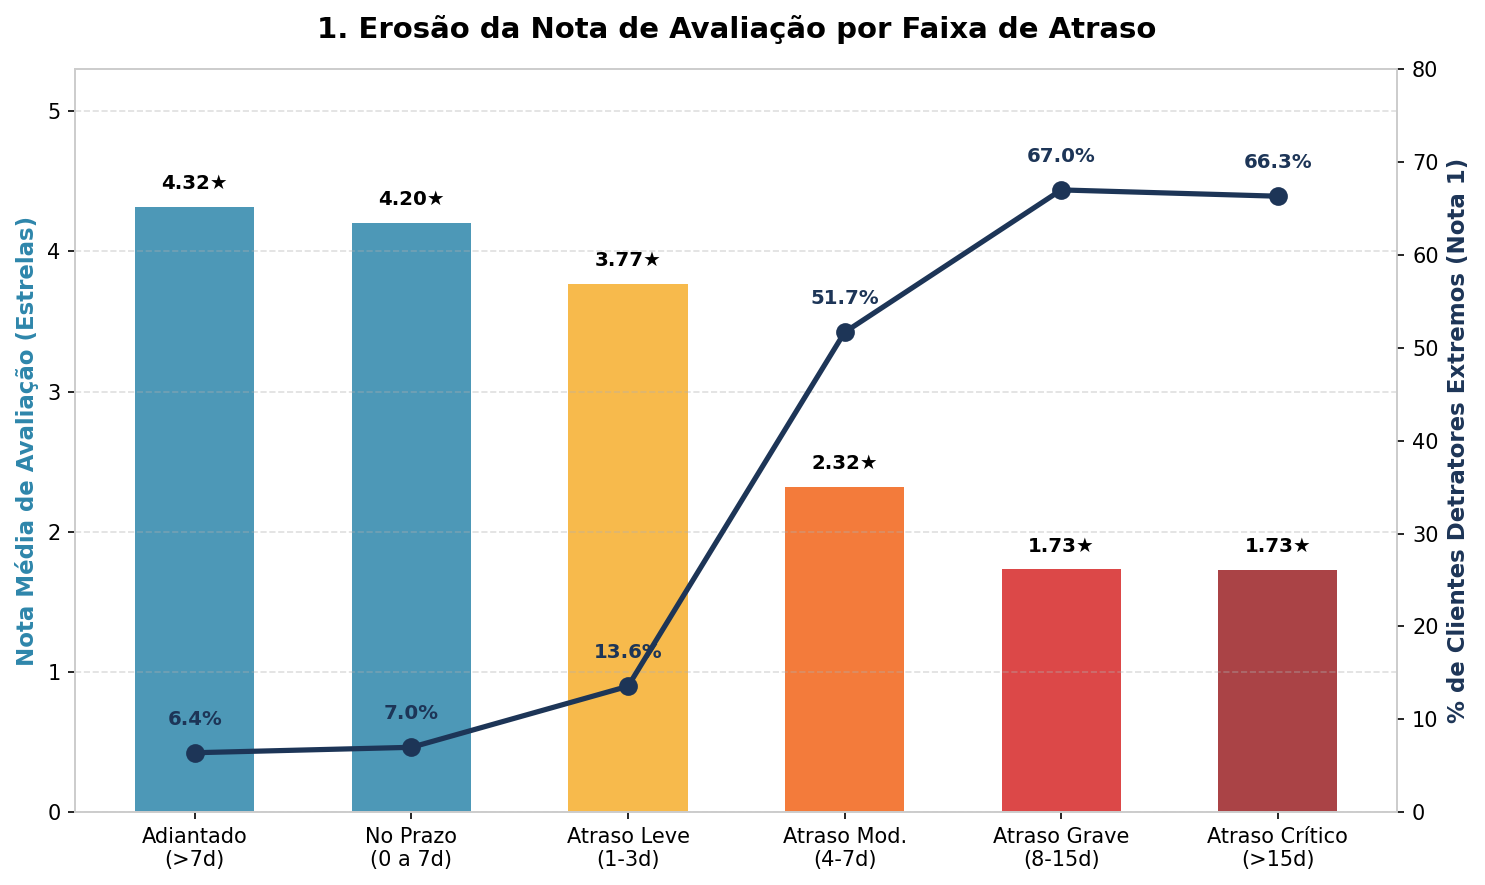

In [ ]:
# ==============================================================================
# GRÁFICO 1: EROSÃO DA NOTA DE AVALIAÇÃO POR FAIXA DE ATRASO (BUCKETS)
# ==============================================================================

# 1. Criação das faixas (bins) de atraso em dias
bins = [-1000, -7, 0, 3, 7, 15, 1000]
labels = [
    'Adiantado\n(>7d)', 'No Prazo\n(0 a 7d)', 'Atraso Leve\n(1-3d)',
    'Atraso Mod.\n(4-7d)', 'Atraso Grave\n(8-15d)', 'Atraso Crítico\n(>15d)'
]
delivered['delay_bucket'] = pd.cut(delivered['delay_days'], bins=bins, labels=labels)

# 2. Cálculo da nota média e do percentual de avaliações 1 estrela em cada faixa
bucket_summary = delivered.groupby('delay_bucket', observed=False).agg(
    orders=('order_id', 'count'),
    gmv=('payment_value', 'sum'),
    mean_score=('review_score', 'mean'),
    pct_1_star=('review_score', lambda x: (x == 1).mean() * 100)
).reset_index()

# 3. Inicialização da figura com eixo duplo (Barras + Linha)
fig, ax1 = plt.subplots(figsize=(10, 6), dpi=150)
ax1_twin = ax1.twinx()

# Paleta semafórica: Azul (no prazo) -> Amarelo -> Laranja -> Vermelho escuro (atraso crítico)
bar_colors = ['#2E86AB', '#2E86AB', '#F6AE2D', '#F26419', '#D62828', '#9B2226']

# Plotagem das barras (Nota Média de 1 a 5) no eixo esquerdo
bars = ax1.bar(
    labels, bucket_summary['mean_score'],
    color=bar_colors, alpha=0.85, width=0.55, label='Nota Média (1-5 ★)'
)

# Plotagem da linha (% de Notas 1 Estrela) no eixo direito
line = ax1_twin.plot(
    labels, bucket_summary['pct_1_star'],
    color='#1D3557', marker='o', linewidth=2.5, markersize=8, label='% Avaliações Nota 1'
)

# 4. Formatação de títulos, eixos e limites
ax1.set_title('1. Erosão da Nota de Avaliação por Faixa de Atraso', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('Nota Média de Avaliação (Estrelas)', fontweight='bold', color='#2E86AB', fontsize=11)
ax1_twin.set_ylabel('% de Clientes Detratores Extremos (Nota 1)', fontweight='bold', color='#1D3557', fontsize=11)
ax1.set_ylim(0, 5.3)
ax1_twin.set_ylim(0, 80)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# 5. Adição dos rótulos de dados (Data Labels) nas barras e nos pontos da linha
for bar in bars:
    h = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2., h + 0.1,
        f'{h:.2f}★', ha='center', va='bottom', fontsize=9.5, fontweight='bold'
    )

for i, txt in enumerate(bucket_summary['pct_1_star']):
    ax1_twin.annotate(
        f'{txt:.1f}%', (labels[i], txt + 3),
        ha='center', fontsize=9.5, fontweight='bold', color='#1D3557'
    )

plt.tight_layout()
plt.savefig('grafico_1_erosao_nota_atraso.png', dpi=300)
plt.show()

### 1.2. **Gráfico 2**: Choques Externos (Série Temporal de Atraso vs. Satisfação)

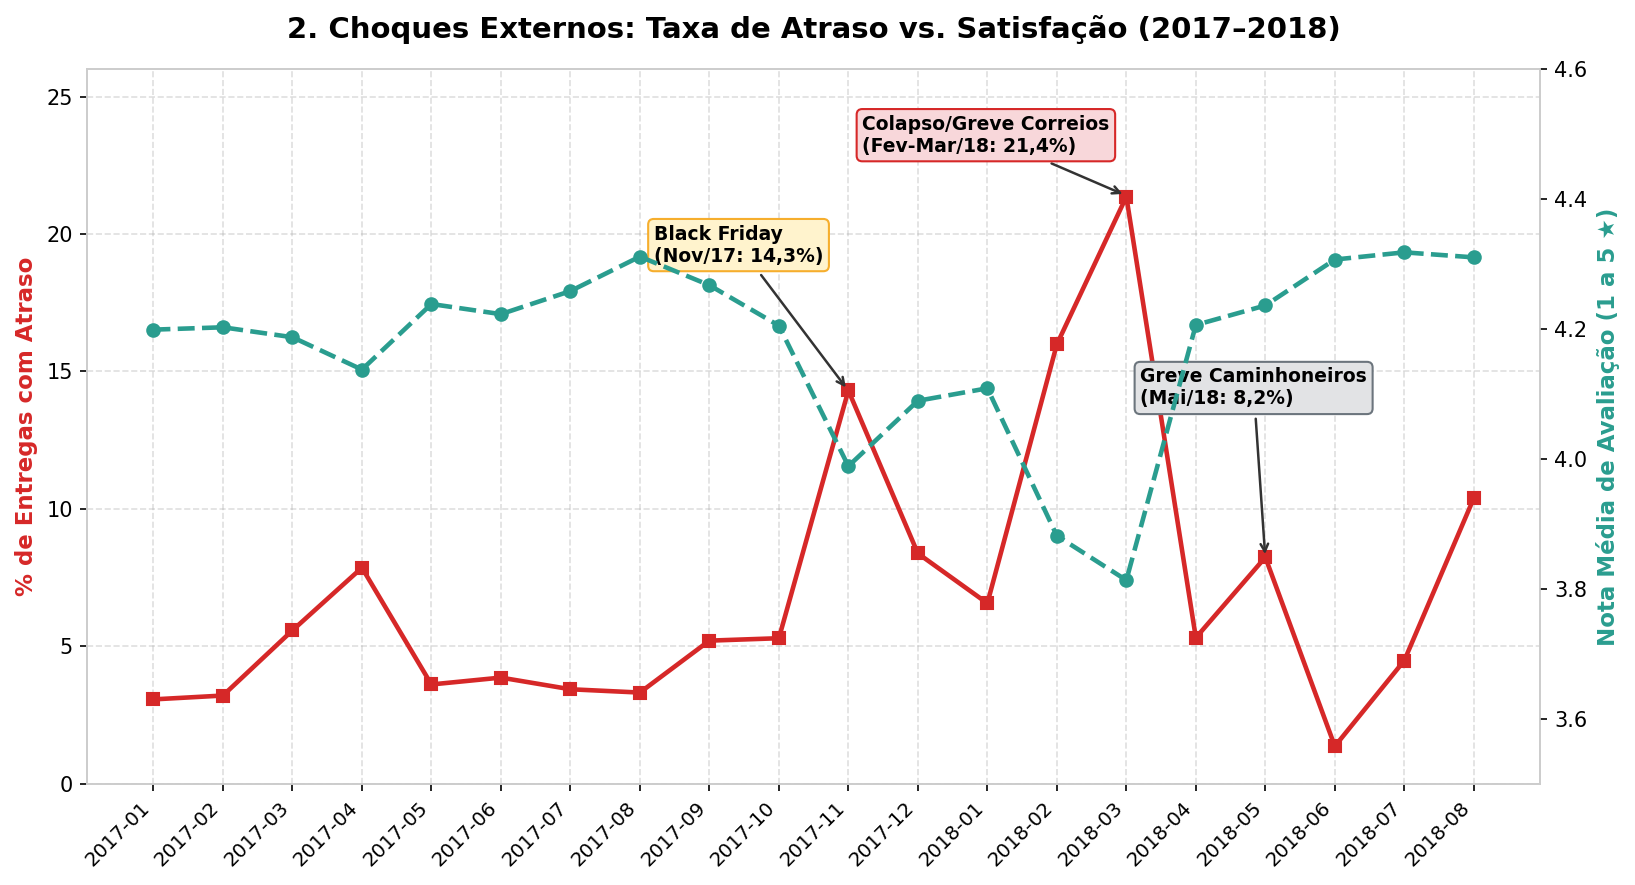

In [ ]:
# ==============================================================================
# GRÁFICO 2: CHOQUES EXTERNOS — TAXA DE ATRASO VS. SATISFAÇÃO (2017–2018)
# ==============================================================================

# 1. Extração do Ano-Mês da compra e agregação mensal
delivered['year_month'] = delivered['order_purchase_timestamp'].dt.to_period('M')

monthly = delivered.groupby('year_month').agg(
    orders=('order_id', 'count'),
    gmv=('payment_value', 'sum'),
    late_rate=('is_late_exact', lambda x: x.mean() * 100),
    mean_score=('review_score', 'mean')
).reset_index()

# Recorte temporal (Janeiro/2017 a Agosto/2018, onde há volume consolidado)
m_data = monthly[(monthly['year_month'] >= '2017-01') & (monthly['year_month'] <= '2018-08')].copy()
m_labels = m_data['year_month'].astype(str).tolist()

# 2. Inicialização da figura com eixo duplo
fig, ax2 = plt.subplots(figsize=(11, 6), dpi=150)
ax2_twin = ax2.twinx()

# Eixo esquerdo (Linha contínua vermelha): % de Entregas com Atraso
ax2.plot(
    m_labels, m_data['late_rate'],
    color='#D62828', marker='s', linewidth=2.2, label='% Pedidos Atrasados'
)

# Eixo direito (Linha tracejada verde): Nota Média de Avaliação
ax2_twin.plot(
    m_labels, m_data['mean_score'],
    color='#2A9D8F', marker='o', linewidth=2.2, linestyle='--', label='Nota Média (Estrelas)'
)

# 3. Formatação dos eixos e grades
ax2.set_title('2. Choques Externos: Taxa de Atraso vs. Satisfação (2017–2018)', fontsize=14, fontweight='bold', pad=15)
ax2.set_ylabel('% de Entregas com Atraso', fontweight='bold', color='#D62828', fontsize=11)
ax2_twin.set_ylabel('Nota Média de Avaliação (1 a 5 ★)', fontweight='bold', color='#2A9D8F', fontsize=11)
ax2.set_xticks(range(len(m_labels)))
ax2.set_xticklabels(m_labels, rotation=45, ha='right', fontsize=9.5)
ax2.set_ylim(0, 26)
ax2_twin.set_ylim(3.5, 4.6)
ax2.grid(True, linestyle='--', alpha=0.4)

# 4. Caixas de anotação destacando os choques logísticos externos da época
# Índice 10 = 2017-11 | Índice 14 = 2018-03 | Índice 16 = 2018-05
ax2.annotate(
    'Black Friday\n(Nov/17: 14,3%)', xy=(10, 14.3), xytext=(7.2, 19),
    arrowprops=dict(arrowstyle='->', color='#333', lw=1.2), fontsize=9, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF3CD', edgecolor='#F6AE2D')
)
ax2.annotate(
    'Colapso/Greve Correios\n(Fev-Mar/18: 21,4%)', xy=(14, 21.4), xytext=(10.2, 23),
    arrowprops=dict(arrowstyle='->', color='#333', lw=1.2), fontsize=9, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#F8D7DA', edgecolor='#D62828')
)
ax2.annotate(
    'Greve Caminhoneiros\n(Mai/18: 8,2%)', xy=(16, 8.2), xytext=(14.2, 13.8),
    arrowprops=dict(arrowstyle='->', color='#333', lw=1.2), fontsize=9, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#E2E3E5', edgecolor='#6C757D')
)

plt.tight_layout()
plt.savefig('grafico_2_choques_externos_mensal.png', dpi=300)
plt.show()

### 1.3. **Gráfico 3**: Assimetria Regional (Peso do Frete vs. Taxa de Atraso)

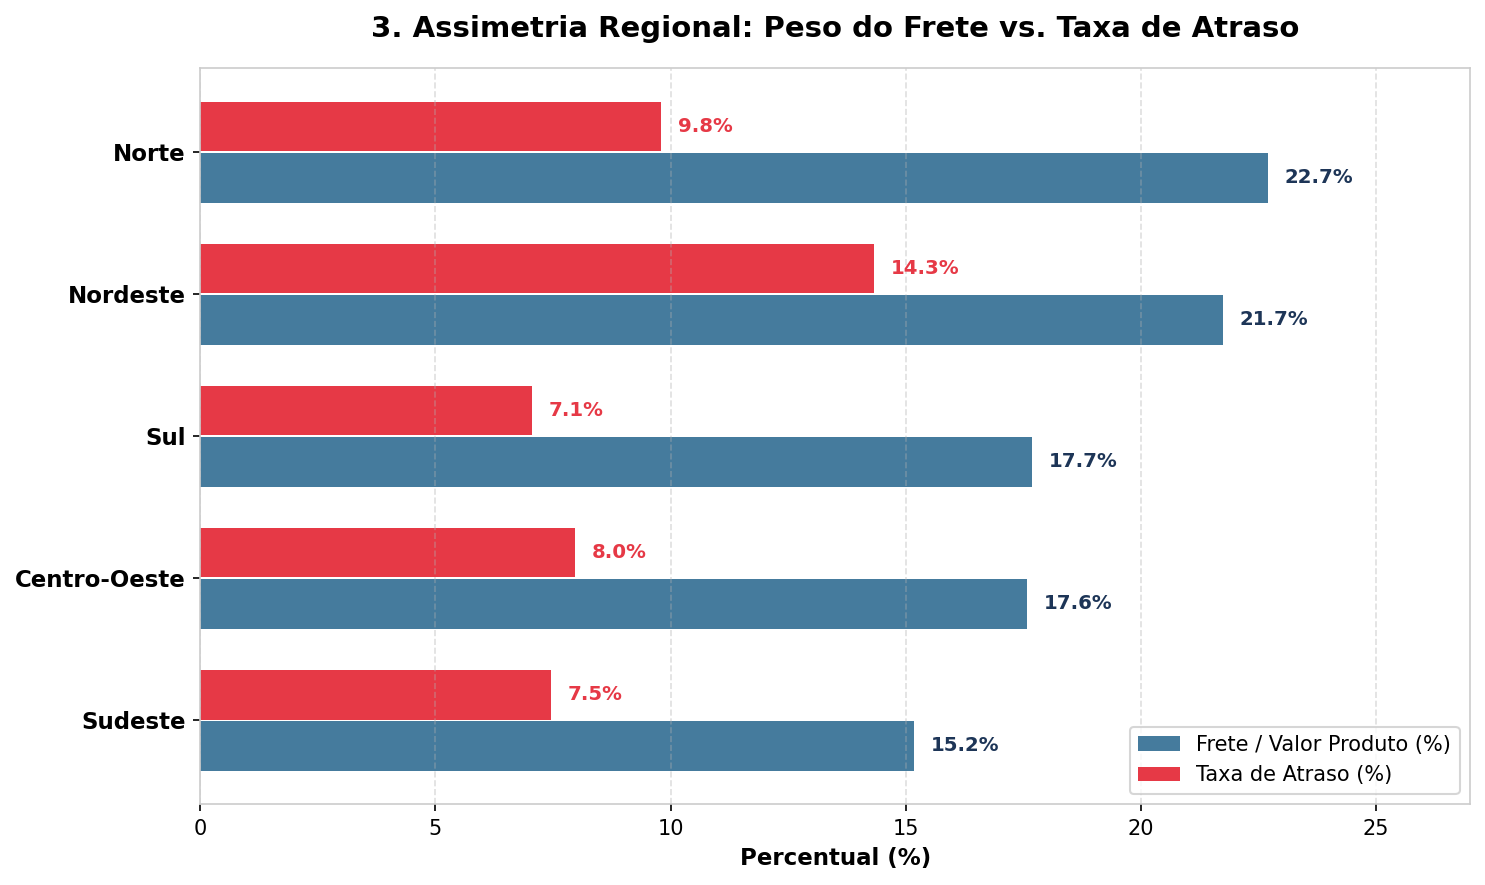

In [ ]:
# ==============================================================================
# GRÁFICO 3: ASSIMETRIA REGIONAL — PESO DO FRETE VS. TAXA DE ATRASO
# ==============================================================================

# 1. Mapeamento das Unidades Federativas (UF) para as 5 Macro-Regiões do Brasil
region_map = {
    'SP': 'Sudeste', 'RJ': 'Sudeste', 'MG': 'Sudeste', 'ES': 'Sudeste',
    'PR': 'Sul', 'SC': 'Sul', 'RS': 'Sul',
    'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'DF': 'Centro-Oeste',
    'BA': 'Nordeste', 'PE': 'Nordeste', 'CE': 'Nordeste', 'RN': 'Nordeste', 'PB': 'Nordeste',
    'AL': 'Nordeste', 'SE': 'Nordeste', 'MA': 'Nordeste', 'PI': 'Nordeste',
    'AM': 'Norte', 'PA': 'Norte', 'AC': 'Norte', 'RO': 'Norte', 'RR': 'Norte', 'AP': 'Norte', 'TO': 'Norte'
}
delivered['region'] = delivered['customer_state'].map(region_map)

# 2. Cálculo da Taxa de Atraso e da Razão Frete/Produto (Freight Ratio) por região
reg_summary = delivered.groupby('region').agg(
    orders=('order_id', 'count'),
    late_rate=('is_late_exact', lambda x: x.mean() * 100),
    freight_to_price_pct=('freight_sum', lambda x: x.sum() / delivered.loc[x.index, 'price_sum'].sum() * 100)
).reset_index()

# Ordenação pelo peso do frete para melhor leitura visual
reg_plot = reg_summary.sort_values('freight_to_price_pct')
y_pos = np.arange(len(reg_plot))

# 3. Criação do gráfico de barras horizontais agrupadas
fig, ax3 = plt.subplots(figsize=(10, 6), dpi=150)

bars3_1 = ax3.barh(
    y_pos - 0.18, reg_plot['freight_to_price_pct'],
    height=0.35, color='#457B9D', label='Frete / Valor Produto (%)'
)
bars3_2 = ax3.barh(
    y_pos + 0.18, reg_plot['late_rate'],
    height=0.35, color='#E63946', label='Taxa de Atraso (%)'
)

# 4. Formatação de eixos, legenda e limites
ax3.set_yticks(y_pos)
ax3.set_yticklabels(reg_plot['region'], fontweight='bold', fontsize=11)
ax3.set_xlabel('Percentual (%)', fontweight='bold', fontsize=11)
ax3.set_title('3. Assimetria Regional: Peso do Frete vs. Taxa de Atraso', fontsize=14, fontweight='bold', pad=15)
ax3.set_xlim(0, 27)
ax3.legend(loc='lower right', fontsize=10)
ax3.grid(axis='x', linestyle='--', alpha=0.4)

# 5. Rótulos percentuais na ponta de cada barra
for bar in bars3_1:
    w = bar.get_width()
    ax3.text(
        w + 0.35, bar.get_y() + bar.get_height() / 2.,
        f'{w:.1f}%', va='center', fontsize=9.5, color='#1D3557', fontweight='bold'
    )
for bar in bars3_2:
    w = bar.get_width()
    ax3.text(
        w + 0.35, bar.get_y() + bar.get_height() / 2.,
        f'{w:.1f}%', va='center', fontsize=9.5, color='#E63946', fontweight='bold'
    )

plt.tight_layout()
plt.savefig('grafico_3_assimetria_regional.png', dpi=300)
plt.show()

### 1.4. **Gráfico 4**: Exposição Financeira Direta à Falha Operacional (GMV em Risco)

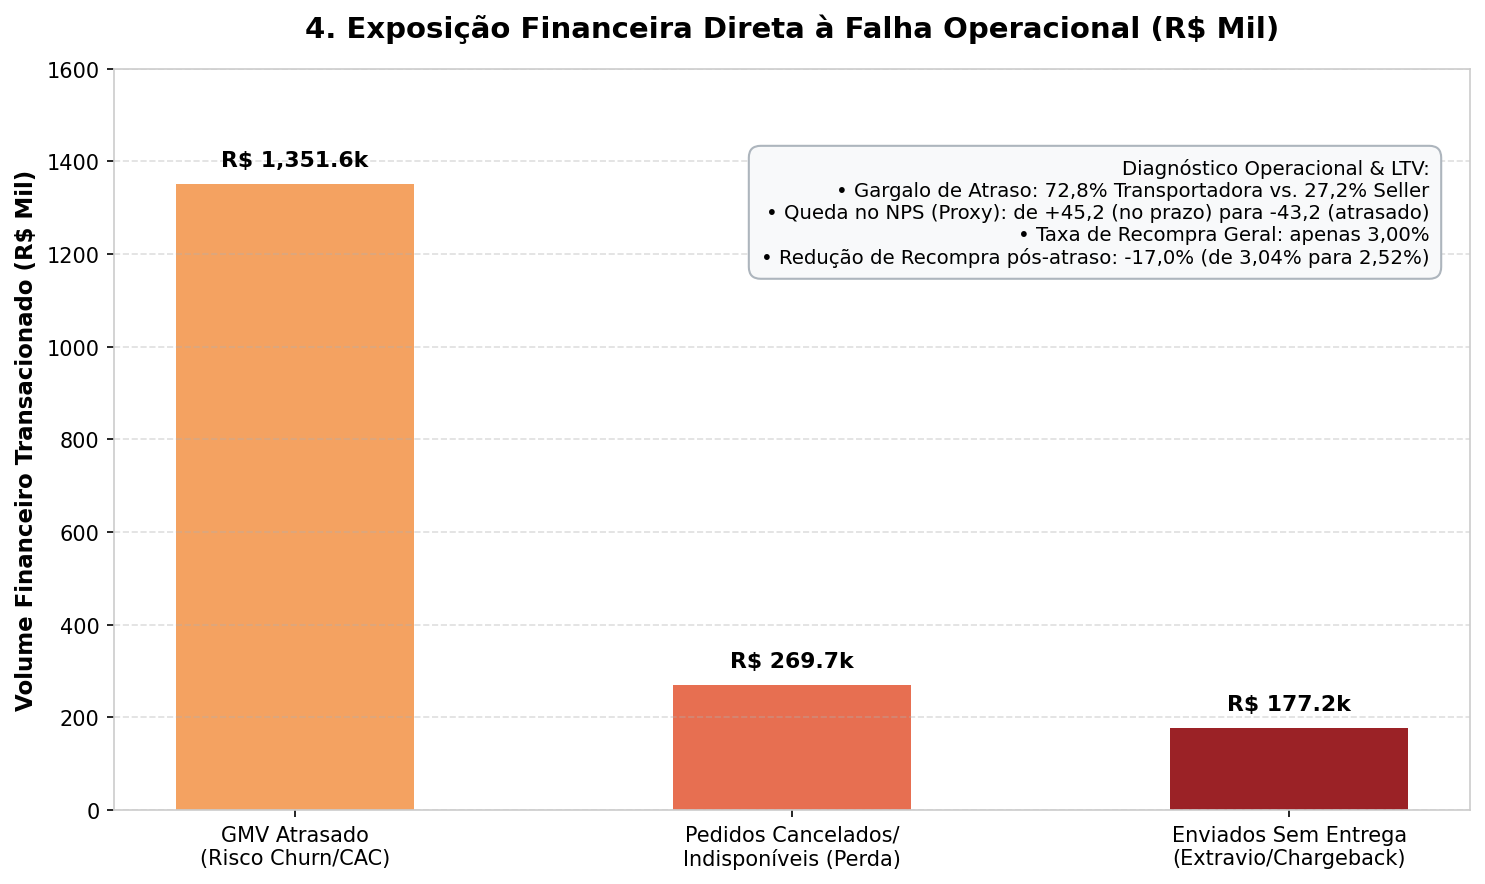

In [ ]:
# ==============================================================================
# GRÁFICO 4: EXPOSIÇÃO FINANCEIRA DIRETA À FALHA OPERACIONAL (R$ MIL)
# ==============================================================================

# 1. Cálculo dos montantes financeiros em risco (convertidos para R$ Milhares)
# GMV entregue com atraso (risco de perda de LTV e aumento do CAC efetivo)
gmv_late = delivered[delivered['is_late_exact'] == True]['payment_value'].sum() / 1e3

# GMV perdido diretamente por pedidos cancelados ou indisponíveis
gmv_canceled = df[df['order_status'].isin(['canceled', 'unavailable'])]['payment_value'].sum() / 1e3

# GMV estagnado no status 'shipped' (despachado ao transportador, mas sem baixa de entrega)
gmv_shipped = df[df['order_status'] == 'shipped']['payment_value'].sum() / 1e3

# 2. Definição das categorias e plotagem das barras
fig, ax4 = plt.subplots(figsize=(10, 6), dpi=150)

categories = [
    'GMV Atrasado\n(Risco Churn/CAC)',
    'Pedidos Cancelados/\nIndisponíveis (Perda)',
    'Enviados Sem Entrega\n(Extravio/Chargeback)'
]
values = [gmv_late, gmv_canceled, gmv_shipped]
colors4 = ['#F4A261', '#E76F51', '#9B2226']

bars4 = ax4.bar(categories, values, color=colors4, width=0.48)

# 3. Formatação visual do gráfico
ax4.set_title('4. Exposição Financeira Direta à Falha Operacional (R$ Mil)', fontsize=14, fontweight='bold', pad=15)
ax4.set_ylabel('Volume Financeiro Transacionado (R$ Mil)', fontweight='bold', fontsize=11)
ax4.set_ylim(0, 1600)
ax4.grid(axis='y', linestyle='--', alpha=0.4)

# 4. Rótulos de valores em Reais no topo de cada barra
for bar in bars4:
    h = bar.get_height()
    ax4.text(
        bar.get_x() + bar.get_width() / 2., h + 30,
        f'R$ {h:,.1f}k', ha='center', va='bottom', fontsize=10.5, fontweight='bold'
    )

# 5. Quadro executivo complementar com indicadores de retenção (LTV), NPS e gargalo
textstr = (
    "Diagnóstico Operacional & LTV:\n"
    "• Gargalo de Atraso: 72,8% Transportadora vs. 27,2% Seller\n"
    "• Queda no NPS (Proxy): de +45,2 (no prazo) para -43,2 (atrasado)\n"
    "• Taxa de Recompra Geral: apenas 3,00%\n"
    "• Redução de Recompra pós-atraso: -17,0% (de 3,04% para 2,52%)"
)
ax4.text(
    0.97, 0.88, textstr, transform=ax4.transAxes, fontsize=9.5,
    verticalalignment='top', horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.6', facecolor='#F8F9FA', edgecolor='#ADB5BD', lw=1)
)

plt.tight_layout()
plt.savefig('grafico_4_exposicao_financeira_gmv.png', dpi=300)
plt.show()

## 2. Conclusão

A análise aprofundada do ecossistema da Olist entre 2016 e 2018 permitiu responder à pergunta norteadora deste projeto, evidenciando que a experiência do cliente e a eficiência logística não constituem apenas um centro de custo operacional, mas sim o principal alicerce da sustentabilidade financeira e do valor de longo prazo de um marketplace (value creation).

Os dados demonstraram que falhas na cadeia de entrega geram uma reação em cadeia destrutiva sobre os pilares econômicos do negócio:

1.   **Destruição de Receita Recorrente e LTV**: Atrasos superiores a três dias provocam o chamado "Abismo do 4º Dia", elevando a proporção de detratores extremos (nota 1) para mais de 51% e reduzindo a taxa de recompra dos clientes em 17,0% (de 3,04% para 2,52%). Em um modelo onde o Custo de Aquisição de Cliente (CAC) é absorvido na primeira compra, a ausência de recompra impede a diluição do investimento inicial e corrói o Lifetime Value (LTV).
2.   **Exposição de GMV e Vazamento de Caixa**: A operação acumulou perdas e riscos severos com R$ 1.351,6 mil em GMV entregue com atraso, somados a R$ 269,7 mil em pedidos cancelados e R$ 177,2 mil em mercadorias estagnadas sem confirmação de entrega (shipped), gerando passivos diretos de chargebacks, estornos e insatisfação sistêmica de lojistas (churn de sellers).
3.   **Vulnerabilidade Estrutural e Assimetria Geográfica**: A dependência quase exclusiva de uma malha postal pública engessada expôs a plataforma a colapsos operacionais durante choques macroeconômicos sazonais e greves sistêmicas (como a Black Friday de 2017 e as paralisações de 2018). Adicionalmente, a alta concentração de vendedores no eixo Sudeste-Sul impôs sobrecustos logísticos (fretes superiores a 21% do valor do item) e taxas de atraso alarmantes (até 23,9% em estados como Alagoas), limitando severamente o potencial de expansão geográfica da empresa.

Diante desse diagnóstico, conclui-se que o modelo puramente asset-light desorquestrado é insustentável para a escala de longo prazo. Propõe-se, portanto, a estruturação de uma camada de inteligência e consolidação logística (4PL / Cross-Docking regional com rotas otimizadas e integração de transportadoras privadas). Ao centralizar coletas (Milk-Run) nos polos de alta densidade de lojistas em São Paulo e Minas Gerais e utilizar algoritmos preditivos de SLA, a companhia é capaz de mitigar os gargalos de first-mile e last-mile, transformar o frete de centro de custo em uma nova linha de receita recorrente, proteger o Valuation e blindar os acionistas contra a volatilidade operacional.

